# BB PPM：LER 差异诊断记录

本 Notebook 汇总独立诊断任务的真实结果。这里执行的单元只读取内嵌快照、显示表格和绘图，**不会采样或调用解码器**。原论文参数扫点 Notebook 和原始结果保持不变。

各项通常含 50 shots，物理噪声参数为 $p=0.001$，但电路、噪声消融和 decoder 控制具有不同条件。不同物理条件不能合成同一条 LER 曲线。`pending` / `decoding` 项不显示推测计数。

`converged` 在本文统一表示返回纠正满足所有 syndrome 约束（残差为零）；分类名中的 `correct` 只表示全部受测 observable 匹配。**`unconverged_correct` 仍然是无效纠正，不能称为有效纠错成功。** LSD 行中的 `converged` 表示 LSD 返回纠正有效，并不是原 Relay-BP 自身收敛。

[论文 Appendix A.7](https://arxiv.org/html/2506.03094v1#A7) 的定义先要求返回纠正满足 $Hc=s$，再比较 $Ac=Ae$。原 Sinter 统计只比较 observable，因此本报告保留原计数并明确称为 **observable-mismatch rate**，同时单独报告 `invalid_corrections`（syndrome 残差非零）。只有 `converged_correct` 同时满足这两个条件；原来的 12/50 不会被静默替换。

Relay-BP 任务按 manifest 报告实际并行方式。多数任务使用 **64 Rayon threads**；恢复后的 baseline 和 clipped100 使用最多 **64 个单核 worker 进程**处理 50 个 shot，并逐 shot 保存检查点，不是每个 worker 开 64 线程。LSD 后处理另列实际 worker 数。恢复运行复用全部原输入，不重新采样；之前两次 SIGTERM 中断的原因未知，中断尝试不算完成结果，其 manifest 和恢复 launch 记录保留在 metadata。50 次未见失败不能验证论文的极低 LER。历史 sweep 没有保存逐 shot 原始样本，因此不能声称与历史输入做过直接逐位比较；本报告的同输入对照是指本次保留的 baseline batch。

“参考配置”指当前实现使用的参数；现代 Relay 源码与数值已核对，但尚未证明作者历史后端的全部实现细节一致。相关参数审计与 LSD 独立复算证据保存在 metadata。若引用 `residual_phases.json`，它记录的是 decoder 的 **syndrome 残差所在 detector 区域，不是物理故障位置**。


In [1]:
import json
import io
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Display inputs only. Full per-shot records, audit reports, and scripts are in metadata.
DATA = {'generated_utc': '2026-11-16T10:23:13.082589+00:00',
 'mode': 'required cases complete',
 'cases': [{'case': 'full_original',
            'status': 'complete',
            'shots': 50,
            'errors': 12,
            'invalid_corrections': 33,
            'converged_correct': 17,
            'converged_wrong': 0,
            'unconverged_correct': 21,
            'unconverged_wrong': 12,
            'seconds': 10295.350863963016,
            'observable_mismatch_rate': 0.24,
            'physical_noise_change': 'unchanged full circuit',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'same retained baseline shots; no resampling during recovery',
            'execution_parallelism': 'up to 64 single-core worker processes; at most 50 shot tasks',
            'scope_note': 'Original compound sequence. Recovered using per-shot checkpoints after the '
                          'previous attempt received SIGTERM for an unknown reason; the interrupted attempt '
                          'has no completed result and is retained as provenance. Up to 64 single-core '
                          'workers for 50 shots. No direct comparison to unavailable historical raw shots. '
                          'Wall time of this final checkpointed execution attempt, including worker '
                          'initialization and collection; earlier interrupted attempts are listed separately '
                          'in manifest.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'Wall time of this final checkpointed execution attempt, including worker '
                             'initialization and collection; earlier interrupted attempts are listed '
                             'separately in manifest.'},
           {'case': 'full_sparse',
            'status': 'complete',
            'shots': 50,
            'errors': 8,
            'invalid_corrections': 39,
            'converged_correct': 11,
            'converged_wrong': 0,
            'unconverged_correct': 31,
            'unconverged_wrong': 8,
            'seconds': 11993.851318901987,
            'observable_mismatch_rate': 0.16,
            'physical_noise_change': 'unchanged full circuit',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'same baseline shots; invertible syndrome transformation',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': 'Only detector annotations change. Fresh DEM also permutes error-variable columns; '
                          'this is an equivalent-representation control.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'full_sparse_fixed_columns_first80',
            'status': 'complete',
            'shots': 50,
            'errors': 8,
            'invalid_corrections': 40,
            'converged_correct': 10,
            'converged_wrong': 0,
            'unconverged_correct': 32,
            'unconverged_wrong': 8,
            'seconds': 36.44887841097079,
            'observable_mismatch_rate': 0.16,
            'physical_noise_change': 'unchanged full circuit',
            'decoder_change': 'changed: first 80 BP iterations only; num_sets=0',
            'input_relation': 'same baseline shots; invertible syndrome transformation',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': "H'=T H, with original error-variable column order, O and priors retained. Compare "
                          'to first_leg; isolates detector basis without fresh-DEM column permutation.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 0,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'full_lifetime_trimmed',
            'status': 'complete',
            'shots': 50,
            'errors': 12,
            'invalid_corrections': 32,
            'converged_correct': 18,
            'converged_wrong': 0,
            'unconverged_correct': 20,
            'unconverged_wrong': 12,
            'seconds': 11070.14072086499,
            'observable_mismatch_rate': 0.24,
            'physical_noise_change': 'modified: remove avoidable check-ancilla idle exposure',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': 'Timing control; ideal circuit and H/O match, priors change. New samples, not a '
                          'same-shot decoder comparison.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'no_idle_noise',
            'status': 'complete',
            'shots': 50,
            'errors': 5,
            'invalid_corrections': 20,
            'converged_correct': 30,
            'converged_wrong': 0,
            'unconverged_correct': 15,
            'unconverged_wrong': 5,
            'seconds': 11998.33861927106,
            'observable_mismatch_rate': 0.1,
            'physical_noise_change': 'modified: all idle noise removed',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': 'Artificial noise ablation, not the paper experiment.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'only_shift_noise',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 11.13758202304598,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'modified: noise only during shift phases',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': 'Artificial phase-noise ablation.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'memory_10',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 5.854033832903951,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'different circuit: 10 storage cycles',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': '',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'shift_y1',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 0.9625096149975434,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'different circuit: isolated shift y=1',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': '',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'shift_y5',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 0.7578441699733958,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'different circuit: isolated shift y=5',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': '',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'native_Z1',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 19.340128080104478,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'different circuit: isolated native Z1 measurement',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': '',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'native_X1X7',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 24.27014463604428,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'different circuit: isolated native X1X7 measurement',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': '',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'native_Y1',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 14.750815134029835,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'different circuit: isolated native Y1 measurement',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': '',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'native_Y7',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 53.045132544939406,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'different circuit: isolated native Y7 measurement',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': '',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'storage_70',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 1160.7535673540551,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'different circuit: 70 storage cycles',
            'decoder_change': 'reference Relay-BP (600 sets)',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': '',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'storage_70_first80',
            'status': 'complete',
            'shots': 50,
            'errors': 5,
            'invalid_corrections': 15,
            'converged_correct': 35,
            'converged_wrong': 0,
            'unconverged_correct': 10,
            'unconverged_wrong': 5,
            'seconds': 20.834706711932085,
            'observable_mismatch_rate': 0.1,
            'physical_noise_change': 'different circuit: 70 storage cycles',
            'decoder_change': 'changed: first 80 BP iterations only; num_sets=0',
            'input_relation': 'same retained storage_70 shots; not the full_PPM baseline shots',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': 'Length control with truncated decoder; not the complete 600-relay reference '
                          'configuration. Compared with storage_70 on exactly the same retained batch, so '
                          'the effect of completing the relay can be assessed within the storage circuit.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 0,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'repeated_Y1_7_first80',
            'status': 'complete',
            'shots': 50,
            'errors': 21,
            'invalid_corrections': 35,
            'converged_correct': 15,
            'converged_wrong': 0,
            'unconverged_correct': 14,
            'unconverged_wrong': 21,
            'seconds': 48.0256356690079,
            'observable_mismatch_rate': 0.42,
            'physical_noise_change': 'different circuit: seven native Y1 measurements',
            'decoder_change': 'changed: first 80 BP iterations only; num_sets=0',
            'input_relation': 'new retained 50-shot batch',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': 'Length/composition control with truncated decoder; not the complete 600-relay '
                          'paper configuration.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 0,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'first_leg',
            'status': 'complete',
            'shots': 50,
            'errors': 12,
            'invalid_corrections': 34,
            'converged_correct': 16,
            'converged_wrong': 0,
            'unconverged_correct': 22,
            'unconverged_wrong': 12,
            'seconds': 31.04506237700116,
            'observable_mismatch_rate': 0.24,
            'physical_noise_change': 'unchanged full circuit',
            'decoder_change': 'changed: first 80 BP iterations only; num_sets=0',
            'input_relation': 'same baseline shots',
            'execution_parallelism': '64 Rayon threads',
            'scope_note': 'Diagnostic truncation, not the 600-relay paper configuration.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 0,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'decoder wall time; excludes preparation'},
           {'case': 'first_leg_320',
            'status': 'complete',
            'shots': 50,
            'errors': 1,
            'invalid_corrections': 20,
            'converged_correct': 30,
            'converged_wrong': 0,
            'unconverged_correct': 19,
            'unconverged_wrong': 1,
            'seconds': 401.56767069303896,
            'observable_mismatch_rate': 0.02,
            'physical_noise_change': 'unchanged full circuit',
            'decoder_change': 'changed: at most 320 BP iterations; pre_iter=320, num_sets=0',
            'input_relation': 'same baseline shots; no new sampling',
            'execution_parallelism': '12 Rayon threads; The 34 extended shots used 12 Rayon threads; 16 '
                                     'exact early stops were reused from the 64-thread first80 run. Per-shot '
                                     'computation is independent of Rayon pool size.',
            'scope_note': 'Decoder diagnostic alongside LSD, not the reference 600-relay result. Sixteen '
                          'valid first-80 early stops are reused; the remaining 34 shots run to a '
                          '320-iteration cap. Per-shot origins and the early-stop equivalence check are '
                          'retained in provenance.json. Sum of the measured source-run wall decode times; '
                          'includes all 50 first80 shots and redecoding 34 of them. Not runtime of a single '
                          'pre320 all50 run.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 320,
                                   'num_sets': 0,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0},
            'seconds_scope': 'Sum of the measured source-run wall decode times; includes all 50 first80 '
                             'shots and redecoding 34 of them. Not runtime of a single pre320 all50 run.'},
           {'case': 'clipped100',
            'status': 'complete',
            'shots': 50,
            'errors': 11,
            'invalid_corrections': 25,
            'converged_correct': 25,
            'converged_wrong': 0,
            'unconverged_correct': 14,
            'unconverged_wrong': 11,
            'seconds': 10152.42429917003,
            'observable_mismatch_rate': 0.22,
            'physical_noise_change': 'unchanged full circuit',
            'decoder_change': 'changed: max_data_value=100; retain all 600 relay sets',
            'input_relation': 'same baseline shots; no resampling during recovery',
            'execution_parallelism': 'up to 64 single-core worker processes; at most 50 shot tasks',
            'scope_note': 'Numerical clipping diagnostic, not the original decoder configuration. Recovered '
                          'using per-shot checkpoints after the previous attempt received SIGTERM for an '
                          'unknown reason; that interrupted attempt is not a completed result. Up to 64 '
                          'single-core workers for 50 shots. Wall time of this final checkpointed execution '
                          'attempt, including worker initialization and collection; earlier interrupted '
                          'attempts are listed separately in manifest.',
            'decoder_parameters': {'alpha': 1.0,
                                   'gamma0': 0.125,
                                   'pre_iter': 80,
                                   'num_sets': 600,
                                   'set_max_iter': 60,
                                   'gamma_dist_interval': [-0.24, 0.66],
                                   'stop_nconv': 5,
                                   'stopping_criterion': 'nconv',
                                   'logging': False,
                                   'seed': 0,
                                   'max_data_value': 100.0},
            'seconds_scope': 'Wall time of this final checkpointed execution attempt, including worker '
                             'initialization and collection; earlier interrupted attempts are listed '
                             'separately in manifest.'},
           {'case': 'first_leg_plus_lsd',
            'status': 'complete',
            'shots': 50,
            'errors': 0,
            'invalid_corrections': 0,
            'converged_correct': 50,
            'converged_wrong': 0,
            'unconverged_correct': 0,
            'unconverged_wrong': 0,
            'seconds': 72.9294405230321,
            'observable_mismatch_rate': 0.0,
            'physical_noise_change': 'unchanged full circuit',
            'decoder_change': 'changed: LSD postprocessing of saved first-80-iteration BP posteriors',
            'input_relation': 'same baseline shots and saved first-leg posteriors',
            'execution_parallelism': '8 single-core postprocessing workers',
            'scope_note': 'Alternative decoder control. Eight single-core postprocessing workers; reported '
                          'seconds cover postprocessing only, excluding the first BP leg.',
            'decoder_parameters': None,
            'seconds_scope': 'postprocessing wall time only; excludes initial BP'}],
 'paper_parameters': {'alpha': 1.0,
                      'gamma0': 0.125,
                      'pre_iter': 80,
                      'num_sets': 600,
                      'set_max_iter': 60,
                      'gamma_dist_interval': [-0.24, 0.66],
                      'stop_nconv': 5,
                      'stopping_criterion': 'nconv'},
 'original_data_integrity': {'verified': True},
 'detector_audit': {'deterministic_parity_completeness': {'num_measurements': 15969,
                                                          'num_detectors': 15510,
                                                          'detector_rank': 15504,
                                                          'num_observables': 10,
                                                          'combined_record_rank': 15514,
                                                          'count_determined_measurements': 15514,
                                                          'deterministic_record_relation_space_complete': True},
                    'low_weight_fault_checks': {'four_fault_exhaustive_coverage_complete': True,
                                                'logical_fault_distance_in_DEM_metric_at_least': 5,
                                                'limits': 'This concerns weights of distinct columns of the '
                                                          'exact full undecomposed DEM and the 10 current '
                                                          'observables. It does not prove distance 10, bound '
                                                          'Relay-BP failure rates, or certify equivalence to '
                                                          'the paper physical circuit or 23-correlator '
                                                          'benchmark.'},
                    'bounded_physical_witness_search': {'status': 'timed_out',
                                                        'wall_timeout_seconds': 115,
                                                        'external_wall_limit_seconds': 115},
                    'sparse_detector_control': {'original_H': {'nnz': 4329031, 'column_max': 23},
                                                'transformed_H': {'nnz': 4243165, 'column_max': 18}},
                    'tanner_graph_overlap': {'original': {'tanner_four_cycle_count': 941260508},
                                             'sparse': {'tanner_four_cycle_count': 715935300}}},
 'source_files': [{'case': 'full_original',
                   'path': 'decoder/full_original_p001_resumed/manifest.json',
                   'sha256': '1329b02a2e7ffd9a208e133d2af31fbdc7617a40d9f6be626d52c32f70b925a8'},
                  {'case': 'full_original',
                   'path': 'decoder/full_original_p001_resumed/summary.json',
                   'sha256': '27180ef9108a2acf1967ba7197786b392e0fa842e69488be8ab8b88985e148d7'},
                  {'case': 'full_original',
                   'path': 'decoder/full_original_p001_resumed/shots.json',
                   'sha256': '16dafd9aa1d053335134a06c82f48257a5ab7672fc4cf57b20b772f69c6203d6'},
                  {'case': 'full_sparse',
                   'path': 'runs/full_sparse/manifest.json',
                   'sha256': '16447b01207d594c0e4baf51cf2fbcd41c1b9b33c4686879d460330bdd6e66e8'},
                  {'case': 'full_sparse',
                   'path': 'runs/full_sparse/summary.json',
                   'sha256': '3527186e484803cbf4dbaf6dbbb3c4596d17835d6a4152065edb7091d218f5a9'},
                  {'case': 'full_sparse',
                   'path': 'runs/full_sparse/shots.json',
                   'sha256': '0bee0fa1eb3865e45a4484289e58ae40c8a51f80404a45de85ed8f4dd2aeb20a'},
                  {'case': 'full_sparse_fixed_columns_first80',
                   'path': 'runs/full_sparse_fixed_columns_first80/manifest.json',
                   'sha256': '65a541b8b71e98a6077e533aea10086706f81ae1ac34e04ec3da588af70de82c'},
                  {'case': 'full_sparse_fixed_columns_first80',
                   'path': 'runs/full_sparse_fixed_columns_first80/summary.json',
                   'sha256': 'f3fcbc525b0a81636d55a74ffde02532ded41db66d7e22cdc71608c531c55439'},
                  {'case': 'full_sparse_fixed_columns_first80',
                   'path': 'runs/full_sparse_fixed_columns_first80/shots.json',
                   'sha256': '373be987a64684e6b4bfb5686f1b9df424d4c1c3a340ac3777244528d0e30bca'},
                  {'case': 'full_lifetime_trimmed',
                   'path': 'runs/full_lifetime_trimmed/manifest.json',
                   'sha256': '03a0c027cb4b64d036369bf0baa77d9c903aa24adfca6e4eea73120e15840ae4'},
                  {'case': 'full_lifetime_trimmed',
                   'path': 'runs/full_lifetime_trimmed/summary.json',
                   'sha256': 'e42c80cec8da3ae052cc0183da13041067835fd0071977d653a9a06445add86d'},
                  {'case': 'full_lifetime_trimmed',
                   'path': 'runs/full_lifetime_trimmed/shots.json',
                   'sha256': 'e834e4893d2ddbb8f1218f54384f477f85b93c7c2d7f2e97825f18fe2ddc2f6a'},
                  {'case': 'no_idle_noise',
                   'path': 'runs/no_idle_noise/manifest.json',
                   'sha256': '21e684a96dc006e3d77242a0da213a74e0e1edc82de1b731200eb90329af14fc'},
                  {'case': 'no_idle_noise',
                   'path': 'runs/no_idle_noise/summary.json',
                   'sha256': '85e4968d37031a9bd1b8daf60e4b3854fa91bb240d03b6a3394017fc27c39b98'},
                  {'case': 'no_idle_noise',
                   'path': 'runs/no_idle_noise/shots.json',
                   'sha256': '83eab7c6096a70c5881f229bf55767d1a1e0bda4c5ad9eabade545e9f33285a0'},
                  {'case': 'only_shift_noise',
                   'path': 'runs/only_shift_noise/manifest.json',
                   'sha256': '1a9f65c6d29af186d8ce719ebe000d6cbb6d4c17b33c6d66be7b1b84fc42e682'},
                  {'case': 'only_shift_noise',
                   'path': 'runs/only_shift_noise/summary.json',
                   'sha256': '65176f65ce379f001fb4e29ff7deec81dfd975c63d38cc419a7de42f9c255eb6'},
                  {'case': 'only_shift_noise',
                   'path': 'runs/only_shift_noise/shots.json',
                   'sha256': 'b6b6efd74322eba249f2e8ed613b8b8d443937b9c53fdaf7c832a5efd1a78a86'},
                  {'case': 'memory_10',
                   'path': 'runs/memory_10/manifest.json',
                   'sha256': '72502826f23aa753cf5755e66363de0b443c8dec068a8142fa0d4bb7fb1da9f6'},
                  {'case': 'memory_10',
                   'path': 'runs/memory_10/summary.json',
                   'sha256': 'f6ad0e7bf67ff66a20a0984d9dec759ce7db67e8cbeabbd79f9e4656d0396968'},
                  {'case': 'memory_10',
                   'path': 'runs/memory_10/shots.json',
                   'sha256': 'dcee0cc8c7213da4433f955c958581258dd3e2d0df3e46bb427847de2997c6b8'},
                  {'case': 'shift_y1',
                   'path': 'runs/shift_y1/manifest.json',
                   'sha256': '5f3bd6bb9bf776245ec4cbc33bb64aca342022a2dc70f233979e4469b168d51b'},
                  {'case': 'shift_y1',
                   'path': 'runs/shift_y1/summary.json',
                   'sha256': '11727497b4c5bf37129222ecc6e2129f871f391f467dadf4f6950a1b641fac78'},
                  {'case': 'shift_y1',
                   'path': 'runs/shift_y1/shots.json',
                   'sha256': 'f9ae85d95ac8340ea59b59bdda9eec84da7a8449547a5302ae887cc7c1d4679a'},
                  {'case': 'shift_y5',
                   'path': 'runs/shift_y5/manifest.json',
                   'sha256': 'ac3590a71d2915b63e2409549e3bba0ba3db454a80c1d630d0e0ff94dcb7bc74'},
                  {'case': 'shift_y5',
                   'path': 'runs/shift_y5/summary.json',
                   'sha256': '6ef3f819bd62aefdac445703fc8452dfe1a4d559c45658bb76cdc8c09101a3c8'},
                  {'case': 'shift_y5',
                   'path': 'runs/shift_y5/shots.json',
                   'sha256': '3bc5c6f7210a03669f7139b93658d54954a05bbee1bea99832bf88b4c592b14c'},
                  {'case': 'native_Z1',
                   'path': 'runs/native_Z1/manifest.json',
                   'sha256': 'a71ab7c476357b05770bb29077e1250968fdfde761c3af3dca96f31720ec73c7'},
                  {'case': 'native_Z1',
                   'path': 'runs/native_Z1/summary.json',
                   'sha256': '3cad2471453f759ea41a6c75e4da4e90b92a2f81839a3dfe7b4831971c0b5495'},
                  {'case': 'native_Z1',
                   'path': 'runs/native_Z1/shots.json',
                   'sha256': 'bb063ffa9b2bb69acc97f5ca18ac5678593b563b23226ca44cd5fc08676a5771'},
                  {'case': 'native_X1X7',
                   'path': 'runs/native_X1X7/manifest.json',
                   'sha256': 'a3ecbc3e89f47cdb75c8ea30eef667ac91b7f7f6cf5c86a7dd7fb871f082276d'},
                  {'case': 'native_X1X7',
                   'path': 'runs/native_X1X7/summary.json',
                   'sha256': '4c3ff62dc607b46f0ac843cff047232f53ba0affd3b38f83800d83459731cfbf'},
                  {'case': 'native_X1X7',
                   'path': 'runs/native_X1X7/shots.json',
                   'sha256': '654a86714ef295541bcafbab8d23422475fb16cfdb7e0cdd1d6705f434776876'},
                  {'case': 'native_Y1',
                   'path': 'runs/native_Y1/manifest.json',
                   'sha256': 'b512d34544466715887b7cbeabeaaf53f03bb788e4b401bf09788c5e84a38e4b'},
                  {'case': 'native_Y1',
                   'path': 'runs/native_Y1/summary.json',
                   'sha256': 'bf4f2399b20f4fdcfba8db9018030eb0775976a468b702d76e4fba1578410765'},
                  {'case': 'native_Y1',
                   'path': 'runs/native_Y1/shots.json',
                   'sha256': '5502bdb8e488150f6d59100e9050823221c00592a7428fb2a9e7ce6e55c5cc27'},
                  {'case': 'native_Y7',
                   'path': 'runs/native_Y7/manifest.json',
                   'sha256': 'b5723b1984ff27c5d5cc8ec86f732f73566c6d2be63203ad7ebb1961bfff8687'},
                  {'case': 'native_Y7',
                   'path': 'runs/native_Y7/summary.json',
                   'sha256': '8ef76f9a86c4809b88846bf8f66a885bfb4dc21dea65b7a154f14c8775392464'},
                  {'case': 'native_Y7',
                   'path': 'runs/native_Y7/shots.json',
                   'sha256': '1a80b9752621f5377fac38ac91b8fa028988b346bd7ea5ab15d2a2fa30da0b51'},
                  {'case': 'storage_70',
                   'path': 'runs/storage_70/manifest.json',
                   'sha256': '1c8f29015fa532f089e1e34acdb256670e0ce92f9d532536161deb73749841a4'},
                  {'case': 'storage_70',
                   'path': 'runs/storage_70/summary.json',
                   'sha256': '24ceb8610626c7a3eed0fe0443110365e479e88d36579fec28ab43fbf884f8d8'},
                  {'case': 'storage_70',
                   'path': 'runs/storage_70/shots.json',
                   'sha256': '09d3741626a397ae28d952170fb08ff0b855330098a17a7a495ec9880bded079'},
                  {'case': 'storage_70_first80',
                   'path': 'runs/storage_70_first80/manifest.json',
                   'sha256': '256db860ba0ba7b2195bc532d9efe8a4f68923cec0465b269262027c9f579c1a'},
                  {'case': 'storage_70_first80',
                   'path': 'runs/storage_70_first80/summary.json',
                   'sha256': 'fa4657c6b0ebd7fb7f992350ea9f3b71cfedf5cf0c69bb9876977a3a553c7a8a'},
                  {'case': 'storage_70_first80',
                   'path': 'runs/storage_70_first80/shots.json',
                   'sha256': '19aa9c060f355582c0371dd064b70a568d1b0d61ebcf8ae6c251526eb1595a8f'},
                  {'case': 'repeated_Y1_7_first80',
                   'path': 'runs/repeated_Y1_7_first80/manifest.json',
                   'sha256': 'b352c1de805194227d60e0873c28aa80ff43f35011f959fd7c7b0a4ee46bd9c9'},
                  {'case': 'repeated_Y1_7_first80',
                   'path': 'runs/repeated_Y1_7_first80/summary.json',
                   'sha256': 'c1758eeb870bc413ce8787e4d68c35cba423ce1b6d784d94532472e9428ffa3b'},
                  {'case': 'repeated_Y1_7_first80',
                   'path': 'runs/repeated_Y1_7_first80/shots.json',
                   'sha256': 'b2cc47fc7f035e08b4aa2a5ece0c1730954435a4fd3fe70feed7192134de7c8a'},
                  {'case': 'first_leg',
                   'path': 'decoder/first_leg_p001/manifest.json',
                   'sha256': 'bfb22886c6e334b1e86f7aca892822ab64cdab630e0a5cfc18f59046734c6c78'},
                  {'case': 'first_leg',
                   'path': 'decoder/first_leg_p001/summary.json',
                   'sha256': '2b8757f128b28e79cfb91df42b9cf771fb35fa0334a6c101e14b00fdbc5cc832'},
                  {'case': 'first_leg',
                   'path': 'decoder/first_leg_p001/shots.json',
                   'sha256': '4c45d6c1054e82601ddacedc48862b6c3ae6a4658855517dff819377fc0c5cb1'},
                  {'case': 'first_leg_320',
                   'path': 'decoder/first_leg_320_all50/manifest.json',
                   'sha256': 'fd2c0f58a64e65c355e17140c5fc98ecadf0b108eec7c81882782ac90c9a58f8'},
                  {'case': 'first_leg_320',
                   'path': 'decoder/first_leg_320_all50/summary.json',
                   'sha256': '88928e1f93db9ded245d8763288e77246f2bd95b2c070dc97be555274f5ef23a'},
                  {'case': 'first_leg_320',
                   'path': 'decoder/first_leg_320_all50/shots.json',
                   'sha256': 'de43e04fd71fce20be746014bea8e8d47dcf45b7118cdddacb7379c3725c9762'},
                  {'case': 'clipped100',
                   'path': 'decoder/clipped100_p001_resumed/manifest.json',
                   'sha256': 'd9f78685977efc0c553a948f09a3ebadca89e611d1381aea7a4b1889ef9dd16d'},
                  {'case': 'clipped100',
                   'path': 'decoder/clipped100_p001_resumed/summary.json',
                   'sha256': 'ed2d82992501dd7987e37294d20085b4a3efc2ea5825dcbf0e45fe2d8737b9c0'},
                  {'case': 'clipped100',
                   'path': 'decoder/clipped100_p001_resumed/shots.json',
                   'sha256': 'bac78c28ce76ca6d0f84c30903d24c778a029aed4a118776f6b5cd247338ac2b'},
                  {'case': 'first_leg_plus_lsd',
                   'path': 'decoder/lsd_first_leg_all/summary.json',
                   'sha256': '692461d0c4832f9366b25d272df157fd12e61e42402fbe2b5f39e8d748ab8c4f'},
                  {'case': 'first_leg_plus_lsd',
                   'path': 'decoder/lsd_first_leg_all/all_results.json',
                   'sha256': 'e4e751cb6d68ef5782f00f4fd19b305edea01d112b774f456954cde5c1bd0851'},
                  {'case': 'static audit',
                   'path': 'detectors/detector_causal_audit.json',
                   'sha256': 'cc652d5a06d3efce23bd475daf187cbe5f8da93036a68bff1a6fbf731bd64a0a'},
                  {'case': 'static audit',
                   'path': 'detectors/physical_witness_search/report.json',
                   'sha256': 'a42020369fcf27874f1b31a713edd0f5eaa5d802141633b6e407078a93cf5786'},
                  {'case': 'static audit',
                   'path': 'decoder/full_original_p001/sampler_reproduction.json',
                   'sha256': 'db67b0eda8ae9ae5f68720a42a3618aa6735c03cfcecd64e22b03c33133e87bf'},
                  {'case': 'static audit',
                   'path': 'decoder/call_equivalence.json',
                   'sha256': '1feb67bda61397560df12453d5a5ae0bf8c92112f7b651cf27bf0852542cb8a5'},
                  {'case': 'static audit',
                   'path': 'decoder/checkpoint_runner_validation.json',
                   'sha256': '10b19b08bf15a68813fa83633218c2c4267f2529d8f99a4eea5bcc1d80db6b14'},
                  {'case': 'static audit',
                   'path': 'decoder/full_original_p001/manifest.json',
                   'sha256': '398efe7f96db06ce8e19cae1beca6e32cb9806230d8fadd15785c72456616af9'},
                  {'case': 'static audit',
                   'path': 'decoder/clipped100_p001/manifest.json',
                   'sha256': '8decec15c7becd0144b632537ff036584e4d439492cb3676f7656a5cc2111260'},
                  {'case': 'static audit',
                   'path': 'decoder/full_original_p001_resumed.launch.json',
                   'sha256': '76bbc3d849b11a7dd58852735decee2c6866b3287aa59f32f5d773a374411530'},
                  {'case': 'static audit',
                   'path': 'decoder/clipped100_p001_resumed.launch.json',
                   'sha256': 'ff41012b44a3ff78409354f16335494921636cd130b656bc113d13a7d1f0b683'},
                  {'case': 'static audit',
                   'path': 'decoder/first_leg_p001/residual_phases.json',
                   'sha256': 'e0b7e4ede68bd8ce977944f071e00d4a7600773a9ee942bceb96d32b3cc33c5a'},
                  {'case': 'static audit',
                   'path': 'timing/relay_parameter_audit.json',
                   'sha256': 'bbe78c0c79ffd2e40883d8973a560db553328d0d445312207342c0a9a8d62c33'},
                  {'case': 'static audit',
                   'path': 'decoder/trace_shot0002/numeric_observation.json',
                   'sha256': 'a6da4e7e64c936442eb28c31e1a894e7bb139920ba1194db3d14637dcdf315c6'},
                  {'case': 'static audit',
                   'path': 'decoder/first_leg_320_all50/provenance.json',
                   'sha256': '1825ef5cb29daa74bbc6546a34590659c3ebad6551da723257298a1ff8a05425'},
                  {'case': 'static audit',
                   'path': 'decoder/trace_phase_shot0002/phase_residual_observation.json',
                   'sha256': '875d252ca392ed5dda2b82cd5ca953d428a486d18028106284882f4299236e32'},
                  {'case': 'static audit',
                   'path': 'decoder/long_retry320_shot0002/comparison.json',
                   'sha256': '409fa2dcd941aaa536632774cd1d19646ea84eec254f75a63ff9356a72d8d05c'},
                  {'case': 'static audit',
                   'path': 'decoder/paired_decoder_comparison/summary.json',
                   'sha256': '14b8fd5e4210a93a5100e7a0da91fef96d40ec8a7e9b2548cbfeb694eab21507'},
                  {'case': 'static audit',
                   'path': 'decoder/paired_decoder_comparison/per_shot.json',
                   'sha256': 'ec134c24ee45e2612edf3a747b81c228952e79222f884bc30e031bc1cf393382'},
                  {'case': 'static audit',
                   'path': 'report/lsd_independent_verification.json',
                   'sha256': '8262ba1e6cc3c14728c7acd3a182e8412f6d6dd1c4be696354f165f3049c37d7'},
                  {'case': 'static audit',
                   'path': 'report/baseline_notebook_fingerprints.json',
                   'sha256': '7bda9d91afab3d6ac2aa9cbd0b5eaaf004c3e7d1c72e9d0b7617c760f6e6f0ae'},
                  {'case': 'static audit',
                   'path': 'report/first320_independent_review.json',
                   'sha256': 'db45f44c480c951a51fc6e5ea586d2aa760d7ddbe6b90fab683b52b64eaa2c55'},
                  {'case': 'static audit',
                   'path': 'report/default_ppm_signed_flow_review.json',
                   'sha256': '577a4eceb8c59405661bdaba52b2e7a78f3b295c998d77b98198a3afb954d73b'},
                  {'case': 'static audit',
                   'path': 'report/noise_load_comparison.json',
                   'sha256': '91762b8822bb606180414db8ee8d17eb17aca5c64043f9471cf82af2b72adc44'},
                  {'case': 'static audit',
                   'path': 'report/noise_parameter_review.json',
                   'sha256': '096bdcaf70afd3ec7ec9767b88834614cbdcf2262f0c160944dec4563a02d388'},
                  {'case': 'static audit',
                   'path': 'report/full_lifetime_trimmed_independent_review.json',
                   'sha256': '97efc0d067dcdf352152717db6fe9d0da8f6794a8580b7b276a198b05e182a0d'},
                  {'case': 'static audit',
                   'path': 'report/full_sparse_independent_review.json',
                   'sha256': 'ec08ad0d6b7e0893658d8436d74105717429d00e237cc95411599da02cf99fa9'},
                  {'case': 'static audit',
                   'path': 'report/physical_controls_independent_review.json',
                   'sha256': 'fe440979b424b271b79e66c4aa459550ec9a5db06888fc91351c61a15bb29a85'},
                  {'case': 'static audit',
                   'path': 'report/detector_evidence_review.json',
                   'sha256': 'b303650b132228259b052f446614124e18124610d033d231ec4a9cf3ac661838'},
                  {'case': 'static audit',
                   'path': 'detectors/redundancy_control_report.json',
                   'sha256': 'b9d25f932a2396fbb333d11ef8a854ae7fe4b898793077049acd01109d58e700'},
                  {'case': 'static audit',
                   'path': 'detectors/connected_components.json',
                   'sha256': 'cdc6df2819533ac8e2d6e3d67dc252012296605c064190c7ab61648d47f318bd'},
                  {'case': 'static audit',
                   'path': 'timing/controls_ready.json',
                   'sha256': 'effcc1f37ac79969045d8adc28606f132853660f4bc725ef64561bbd83dc7454'},
                  {'case': 'static audit',
                   'path': 'timing/length_controls/length_controls_report.json',
                   'sha256': '0620e342193a2e50821e29c657bfc30ee32ff1eeb993a40dd27a55e45283e413'},
                  {'case': 'static audit',
                   'path': 'phases/phase_controls.json',
                   'sha256': '1c777aabf64124d2ee05295ee449a369f06be837e599d1097db30193629354e0'},
                  {'case': 'source script',
                   'path': 'decoder/diagnose_decoder.py',
                   'sha256': 'd2e8e7d9cd2d30e534f14ba16b6001f94272fb3905bab1913016a6befd6b3224'},
                  {'case': 'source script',
                   'path': 'decoder/diagnose_decoder_v1.py',
                   'sha256': 'a5d78798e21d42fbeb7576064b16586fe19aad3671499dacd225700ce6ea0dbf'},
                  {'case': 'source script',
                   'path': 'decoder/probe_first_leg.py',
                   'sha256': '0f3eb88519d04014dd39c60a99bebe8c35054296043805e6a49ec39ba3333b84'},
                  {'case': 'source script',
                   'path': 'decoder/probe_clipped.py',
                   'sha256': 'e5cb6cbe56ece9d41f16955610e659ec8245edd1b4027e89ce65df4180f3e231'},
                  {'case': 'source script',
                   'path': 'decoder/try_postprocessor.py',
                   'sha256': '1d34cc2c231fb7af1acba9c1005974a5a27348d70d6ff08db03a89aad29c229c'},
                  {'case': 'source script',
                   'path': 'decoder/run_lsd_batch.py',
                   'sha256': '8a7130ecbdf4031ae54e4617680158db6ce8e4d5f6fb665479ccfb33011298f4'},
                  {'case': 'source script',
                   'path': 'decoder/merge_first_320.py',
                   'sha256': 'edccffea6f67e1fb8f8e5127ca3fb52182e4914f03d435437559974e42f80d14'},
                  {'case': 'source script',
                   'path': 'decoder/run_checkpointed.py',
                   'sha256': '54b32240c291f49023edb0f8fbe495e334a5cfbaf4f78468c1e5f65a4e294bbf'},
                  {'case': 'source script',
                   'path': 'decoder/observe_phase_residuals.py',
                   'sha256': '1cca0dabea00f9eef7fbd27268a8fdecaec3326de69fdeb7bdaed80e0d90960a'},
                  {'case': 'source script',
                   'path': 'decoder/trace_phase_child.py',
                   'sha256': 'b5cde08c094fb4eff76f63b154990ee29eda4c27c0ea7160081aab57313a5149'},
                  {'case': 'source script',
                   'path': 'decoder/plot_phase_residuals.py',
                   'sha256': 'e12b2beab1c8f761ffd6bcee0eaac0c167aa629b79c8d4a4dd9a4a125cf19f49'},
                  {'case': 'source script',
                   'path': 'decoder/probe_one_long_retry.py',
                   'sha256': '7cb64ce6937c7fa9fb3fe00af90b71989a8c7c4a5c98e3553f57a62ad46041e2'},
                  {'case': 'source script',
                   'path': 'report/recheck_physical_controls.py',
                   'sha256': '259ae817f667a7553beac70fc187e958787e54878d53719c1030753a85ef19d4'},
                  {'case': 'source script',
                   'path': 'timing/check_noise_parameters.py',
                   'sha256': 'ac797f132d7fb68884f36384b84410d5e4f08a5bf84f23fe19dc6a2d8574b92d'},
                  {'case': 'source script',
                   'path': 'decoder/compare_controls.py',
                   'sha256': 'c56d3185708c8fc34b85617c71768216dd817df43eb9731d7e84c4ce095aff77'},
                  {'case': 'source script',
                   'path': 'report/review_full_sparse.py',
                   'sha256': '1cbb8a329b1caf7e1f6157e4c78ce305527ecbd4a52226d7d6f34c22b43d668e'},
                  {'case': 'diagnostic figure',
                   'path': 'decoder/trace_phase_shot0002/phase_residuals.png',
                   'sha256': 'f3e2edebe339cfa1c92caeaec843e98aa97b5d51445d138650373497bb82eaa0'}],
 'signed_flow_review': {'actual_default_all_selected_signed_flows_passed': True,
                        'choi_all_23_selected_signed_flows_passed': True,
                        'choi_output_codespace_all_144_declared_checks_positive': True,
                        'actual_default_wrong_target_sign_rejected': True,
                        'choi_wrong_output_sign_rejected': True,
                        'choi_noncommuting_initial_bell_correlation_not_preserved': True,
                        'verification_caveat': 'Stim unsigned=False checks use 256 randomized stabilizer '
                                               'algebra tests internally (documented false-positive bound '
                                               '2^-256 per accepted check). These are not noise/shots/LER '
                                               'sampling. No claim of deterministic symbolic enumeration is '
                                               'made.',
                        'new_physical_samples': 0,
                        'decoder_calls': 0,
                        'exact_circuit_validation': {'rebuilt_from_saved_plan_exactly_equals_original': True},
                        'choi_scope': {'encoded_data_qubits': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
                                       'consumed_pivot': 1,
                                       'pivot_inputs_verified': ['+Z1', '+X1']},
                        'choi_pivot_X_additional_check': {'all_23_selected_signed_flows_passed': True,
                                                          'positive_codespace_all_checks_passed': True,
                                                          'wrong_target_sign_rejected': True,
                                                          'noncommuting_bell_not_preserved': True}},
 'single_shot_diagnostics': {'phase_observer': {'shot_index': 2,
                                                'observed_leg_count': 20,
                                                'all_observed_posteriors_finite': True,
                                                'observed_globally_converged_legs': 0,
                                                'distinct_residual_supports': 20,
                                                'observed_legs': [{'leg': 0,
                                                                   'iterations': 80,
                                                                   'success': False,
                                                                   'residual_weight': 4,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 25884011879.183987},
                                                                  {'leg': 1,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 670,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 24783.12741313831},
                                                                  {'leg': 2,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 407,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 658006.5179220652},
                                                                  {'leg': 3,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 1069,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 26537.984538727844},
                                                                  {'leg': 4,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 748,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 75784.57488839667},
                                                                  {'leg': 5,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 712,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 57875.75743675993},
                                                                  {'leg': 6,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 887,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 20224.86193903254},
                                                                  {'leg': 7,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 1716,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 65695.59699148183},
                                                                  {'leg': 8,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 1137,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 20085.705140650123},
                                                                  {'leg': 9,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 760,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 51372.15778754432},
                                                                  {'leg': 10,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 725,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 46403.55118710494},
                                                                  {'leg': 11,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 958,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 35208.39788468484},
                                                                  {'leg': 12,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 611,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 333587.84063488734},
                                                                  {'leg': 13,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 879,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 316562.59684072074},
                                                                  {'leg': 14,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 446,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 227923.5259320976},
                                                                  {'leg': 15,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 831,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 27156.848196969495},
                                                                  {'leg': 16,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 324,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 75149.96102031964},
                                                                  {'leg': 17,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 640,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 7275.662005493878},
                                                                  {'leg': 18,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 514,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 174964.0754448741},
                                                                  {'leg': 19,
                                                                   'iterations': 60,
                                                                   'success': False,
                                                                   'residual_weight': 914,
                                                                   'nonfinite': 0,
                                                                   'nan': 0,
                                                                   'max_finite_abs': 31825.102246323342}],
                                                'phase_plot_values': {'phase00_measure_Z,I': [3,
                                                                                              10,
                                                                                              8,
                                                                                              35,
                                                                                              167,
                                                                                              3,
                                                                                              192,
                                                                                              287,
                                                                                              71,
                                                                                              51,
                                                                                              64,
                                                                                              3,
                                                                                              230,
                                                                                              21,
                                                                                              8,
                                                                                              398,
                                                                                              14,
                                                                                              55,
                                                                                              0,
                                                                                              281],
                                                                      'phase01_shift_0,5': [0,
                                                                                            18,
                                                                                            0,
                                                                                            0,
                                                                                            0,
                                                                                            0,
                                                                                            0,
                                                                                            14,
                                                                                            58,
                                                                                            33,
                                                                                            36,
                                                                                            0,
                                                                                            0,
                                                                                            0,
                                                                                            2,
                                                                                            109,
                                                                                            16,
                                                                                            0,
                                                                                            0,
                                                                                            116],
                                                                      'phase02_measure_X,X': [1,
                                                                                              3,
                                                                                              4,
                                                                                              10,
                                                                                              36,
                                                                                              4,
                                                                                              9,
                                                                                              36,
                                                                                              276,
                                                                                              18,
                                                                                              242,
                                                                                              282,
                                                                                              203,
                                                                                              8,
                                                                                              272,
                                                                                              49,
                                                                                              4,
                                                                                              17,
                                                                                              8,
                                                                                              97],
                                                                      'phase03_shift_0,1': [0,
                                                                                            0,
                                                                                            0,
                                                                                            0,
                                                                                            1,
                                                                                            15,
                                                                                            2,
                                                                                            2,
                                                                                            0,
                                                                                            4,
                                                                                            0,
                                                                                            76,
                                                                                            128,
                                                                                            4,
                                                                                            9,
                                                                                            3,
                                                                                            0,
                                                                                            0,
                                                                                            5,
                                                                                            0],
                                                                      'phase04_measure_Y,I': [0,
                                                                                              191,
                                                                                              318,
                                                                                              185,
                                                                                              220,
                                                                                              299,
                                                                                              166,
                                                                                              376,
                                                                                              0,
                                                                                              204,
                                                                                              0,
                                                                                              8,
                                                                                              1,
                                                                                              215,
                                                                                              8,
                                                                                              255,
                                                                                              225,
                                                                                              139,
                                                                                              69,
                                                                                              9],
                                                                      'phase05_measure_I,Y': [0,
                                                                                              187,
                                                                                              41,
                                                                                              398,
                                                                                              7,
                                                                                              175,
                                                                                              253,
                                                                                              277,
                                                                                              211,
                                                                                              191,
                                                                                              181,
                                                                                              26,
                                                                                              0,
                                                                                              0,
                                                                                              26,
                                                                                              3,
                                                                                              2,
                                                                                              11,
                                                                                              175,
                                                                                              58],
                                                                      'phase06_measure_Z,I': [0,
                                                                                              38,
                                                                                              0,
                                                                                              49,
                                                                                              289,
                                                                                              122,
                                                                                              2,
                                                                                              208,
                                                                                              264,
                                                                                              231,
                                                                                              177,
                                                                                              230,
                                                                                              2,
                                                                                              296,
                                                                                              12,
                                                                                              8,
                                                                                              15,
                                                                                              3,
                                                                                              17,
                                                                                              4],
                                                                      'phase07_shift_0,5': [0,
                                                                                            8,
                                                                                            0,
                                                                                            4,
                                                                                            1,
                                                                                            6,
                                                                                            0,
                                                                                            2,
                                                                                            1,
                                                                                            17,
                                                                                            5,
                                                                                            38,
                                                                                            1,
                                                                                            7,
                                                                                            0,
                                                                                            0,
                                                                                            0,
                                                                                            3,
                                                                                            4,
                                                                                            0],
                                                                      'phase08_measure_X,X': [0,
                                                                                              9,
                                                                                              17,
                                                                                              8,
                                                                                              2,
                                                                                              66,
                                                                                              232,
                                                                                              306,
                                                                                              239,
                                                                                              4,
                                                                                              0,
                                                                                              289,
                                                                                              26,
                                                                                              64,
                                                                                              38,
                                                                                              0,
                                                                                              43,
                                                                                              353,
                                                                                              5,
                                                                                              256],
                                                                      'phase09_shift_0,1': [0,
                                                                                            0,
                                                                                            10,
                                                                                            0,
                                                                                            0,
                                                                                            9,
                                                                                            31,
                                                                                            3,
                                                                                            4,
                                                                                            4,
                                                                                            0,
                                                                                            0,
                                                                                            4,
                                                                                            17,
                                                                                            62,
                                                                                            0,
                                                                                            0,
                                                                                            0,
                                                                                            0,
                                                                                            91],
                                                                      'phase10_measure_Y,I': [0,
                                                                                              206,
                                                                                              9,
                                                                                              380,
                                                                                              25,
                                                                                              13,
                                                                                              0,
                                                                                              205,
                                                                                              13,
                                                                                              3,
                                                                                              20,
                                                                                              6,
                                                                                              11,
                                                                                              188,
                                                                                              9,
                                                                                              6,
                                                                                              3,
                                                                                              55,
                                                                                              231,
                                                                                              2]}},
                             'retry_counterfactual': {'original_first_retry60': {'leg': 1,
                                                                                 'iterations': 60,
                                                                                 'success': False,
                                                                                 'residual_weight': 670,
                                                                                 'nonfinite': 0,
                                                                                 'nan': 0,
                                                                                 'max_finite_abs': 24783.12741313831},
                                                      'extended_first_retry320': {'leg': 1,
                                                                                  'iterations': 320,
                                                                                  'success': False,
                                                                                  'residual_weight': 799,
                                                                                  'nonfinite': 0,
                                                                                  'nan': 0,
                                                                                  'max_finite_abs': 45433.76724729366},
                                                      'returned_result': {'success': False,
                                                                          'logical_failure': True,
                                                                          'residual_weight': 4,
                                                                          'iterations': 400,
                                                                          'returned_leg_budget': 80,
                                                                          'decode_seconds': 137.86159073992167,
                                                                          'note': 'If neither leg converges, '
                                                                                  'Relay returns the initial '
                                                                                  'first80 candidate; the '
                                                                                  'observed320-leg residual '
                                                                                  'is reported '
                                                                                  'separately.'}}},
 'noise_load_comparison': [{'case': 'full_original',
                            'sample_count': 50,
                            'mechanism_prior_sum': 271.60766054990887,
                            'syndrome_mean': 1042.66,
                            'syndrome_min': 926,
                            'syndrome_median': 1041.0,
                            'syndrome_max': 1240},
                           {'case': 'native_Y1',
                            'sample_count': 50,
                            'mechanism_prior_sum': 40.039304309983294,
                            'syndrome_mean': 142.94,
                            'syndrome_min': 96,
                            'syndrome_median': 144.5,
                            'syndrome_max': 193},
                           {'case': 'storage_70',
                            'sample_count': 50,
                            'mechanism_prior_sum': 149.47137481196646,
                            'syndrome_mean': 541.24,
                            'syndrome_min': 443,
                            'syndrome_median': 542.0,
                            'syndrome_max': 657},
                           {'case': 'full_lifetime_trimmed',
                            'sample_count': 50,
                            'mechanism_prior_sum': 226.3495398494475,
                            'syndrome_mean': 946.68,
                            'syndrome_min': 840,
                            'syndrome_median': 944.0,
                            'syndrome_max': 1130},
                           {'case': 'no_idle_noise',
                            'sample_count': 50,
                            'mechanism_prior_sum': 114.84987272486711,
                            'syndrome_mean': 572.82,
                            'syndrome_min': 497,
                            'syndrome_median': 569.0,
                            'syndrome_max': 700},
                           {'case': 'only_shift_noise',
                            'sample_count': 50,
                            'mechanism_prior_sum': 13.577278205199542,
                            'syndrome_mean': 59.7,
                            'syndrome_min': 17,
                            'syndrome_median': 58.0,
                            'syndrome_max': 102}]}
print('Snapshot:', DATA['generated_utc'])
print('Report mode:', DATA['mode'])
print('Source root: . (paths below are relative to causal_diagnostics/)')
print('Original run hashes verified:', DATA['original_data_integrity']['verified'])


Snapshot: 2026-11-16T10:23:13.082589+00:00
Report mode: required cases complete
Source root: . (paths below are relative to causal_diagnostics/)
Original run hashes verified: True


## 条件与输入来源

下表明确每项是否修改物理噪声、电路或 decoder。相同 seed 不等于不同电路使用相同物理 fault 样本。`full_sparse` 是原 baseline syndrome 的可逆变换；fresh DEM 还会重排错误变量列。

附表只描述已经保存的输入，不是解码结果：`mechanism_prior_sum` 是合并 DEM parity 机制的期望个数，**不是物理 fault 数**。`no_idle_noise` 的先验和/平均 syndrome weight 为 114.85/572.82，`storage_70` 为 149.47/541.24；这些来自不同电路与输入批次。平均 syndrome 接近不代表解码难度相同，不能据此给出最终因果解释。

In [2]:
conditions = pd.DataFrame(DATA['cases'])
condition_columns = ['case', 'status', 'physical_noise_change', 'decoder_change', 'input_relation', 'execution_parallelism']
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(conditions[condition_columns])
for item in DATA['cases']:
    if item['scope_note']:
        print(item['case'] + ': ' + item['scope_note'])
load_rows = DATA.get('noise_load_comparison', [])
if load_rows:
    print('Saved input descriptors; these are not decoding results:')
    loads = pd.DataFrame(load_rows)
    for name in ('mechanism_prior_sum', 'syndrome_mean', 'syndrome_median'):
        loads[name] = loads[name].round(2)
    display(loads[['case', 'sample_count', 'mechanism_prior_sum', 'syndrome_mean', 'syndrome_min', 'syndrome_median', 'syndrome_max']])


,case,status,physical_noise_change,decoder_change,input_relation,execution_parallelism
0,full_original,complete,unchanged full circuit,reference Relay-BP (600 sets),same retained baseline shots; no resampling during recovery,up to 64 single-core worker processes; at most 50 shot tasks
1,full_sparse,complete,unchanged full circuit,reference Relay-BP (600 sets),same baseline shots; invertible syndrome transformation,64 Rayon threads
2,full_sparse_fixed_columns_first80,complete,unchanged full circuit,changed: first 80 BP iterations only; num_sets=0,same baseline shots; invertible syndrome transformation,64 Rayon threads
3,full_lifetime_trimmed,complete,modified: remove avoidable check-ancilla idle exposure,reference Relay-BP (600 sets),new retained 50-shot batch,64 Rayon threads
4,no_idle_noise,complete,modified: all idle noise removed,reference Relay-BP (600 sets),new retained 50-shot batch,64 Rayon threads
5,only_shift_noise,complete,modified: noise only during shift phases,reference Relay-BP (600 sets),new retained 50-shot batch,64 Rayon threads
6,memory_10,complete,different circuit: 10 storage cycles,reference Relay-BP (600 sets),new retained 50-shot batch,64 Rayon threads
7,shift_y1,complete,different circuit: isolated shift y=1,reference Relay-BP (600 sets),new retained 50-shot batch,64 Rayon threads
8,shift_y5,complete,different circuit: isolated shift y=5,reference Relay-BP (600 sets),new retained 50-shot batch,64 Rayon threads
9,native_Z1,complete,different circuit: isolated native Z1 measurement,reference Relay-BP (600 sets),new retained 50-shot batch,64 Rayon threads


full_original: Original compound sequence. Recovered using per-shot checkpoints after the previous attempt received SIGTERM for an unknown reason; the interrupted attempt has no completed result and is retained as provenance. Up to 64 single-core workers for 50 shots. No direct comparison to unavailable historical raw shots. Wall time of this final checkpointed execution attempt, including worker initialization and collection; earlier interrupted attempts are listed separately in manifest.
full_sparse: Only detector annotations change. Fresh DEM also permutes error-variable columns; this is an equivalent-representation control.
full_sparse_fixed_columns_first80: H'=T H, with original error-variable column order, O and priors retained. Compare to first_leg; isolates detector basis without fresh-DEM column permutation.
full_lifetime_trimmed: Timing control; ideal circuit and H/O match, priors change. New samples, not a same-shot decoder comparison.
no_idle_noise: Artificial noise ablatio

,case,sample_count,mechanism_prior_sum,syndrome_mean,syndrome_min,syndrome_median,syndrome_max
0,full_original,50,271.61,1042.66,926,1041.0,1240
1,native_Y1,50,40.04,142.94,96,144.5,193
2,storage_70,50,149.47,541.24,443,542.0,657
3,full_lifetime_trimmed,50,226.35,946.68,840,944.0,1130
4,no_idle_noise,50,114.85,572.82,497,569.0,700
5,only_shift_noise,50,13.58,59.70,17,58.0,102


## 实际计数与耗时

`errors` 保留原 observable 不匹配计数；`invalid_corrections` 是不满足 $Hc=s$ 的次数，两者可以重叠，不能相加。`observable_mismatch_rate = errors / shots` 不是保证返回有效纠正的成功率。`seconds` 为各任务记录的 decoder wall time，不含准备步骤。LSD 行只记后处理 wall time，不含前 80 次 BP 迭代；不同并发负载下的耗时不能直接作算法速度排名。

In [3]:
columns = ['case', 'status', 'shots', 'errors', 'invalid_corrections', 'converged_correct', 'converged_wrong', 'unconverged_correct', 'unconverged_wrong', 'seconds']
counts = pd.DataFrame(DATA['cases'])[columns].copy()
for name in columns[2:-1]:
    counts[name] = pd.array(counts[name], dtype='Int64')
counts['observable_mismatch_rate'] = pd.DataFrame(DATA['cases'])['observable_mismatch_rate']
counts['seconds'] = pd.to_numeric(counts['seconds'], errors='coerce').round(3)
with pd.option_context('display.max_rows', None):
    display(counts)
pending = [row['case'] + ' (' + row['status'] + ')' for row in DATA['cases'] if row['status'] != 'complete']
print('Pending/incomplete:', ', '.join(pending) if pending else 'none')


,case,status,shots,errors,invalid_corrections,converged_correct,converged_wrong,unconverged_correct,unconverged_wrong,seconds,observable_mismatch_rate
0,full_original,complete,50,12,33,17,0,21,12,10295.351,0.24
1,full_sparse,complete,50,8,39,11,0,31,8,11993.851,0.16
2,full_sparse_fixed_columns_first80,complete,50,8,40,10,0,32,8,36.449,0.16
3,full_lifetime_trimmed,complete,50,12,32,18,0,20,12,11070.141,0.24
4,no_idle_noise,complete,50,5,20,30,0,15,5,11998.339,0.10
5,only_shift_noise,complete,50,0,0,50,0,0,0,11.138,0.00
6,memory_10,complete,50,0,0,50,0,0,0,5.854,0.00
7,shift_y1,complete,50,0,0,50,0,0,0,0.963,0.00
8,shift_y5,complete,50,0,0,50,0,0,0,0.758,0.00
9,native_Z1,complete,50,0,0,50,0,0,0,19.340,0.00


Pending/incomplete: none


## 收敛与逻辑错误分类

每行独立显示该 case 的 shot 分类；不连接不同 case，也不拟合 LER 曲线。只绘制已完成、通过整数计数和逐 shot 校验的任务。

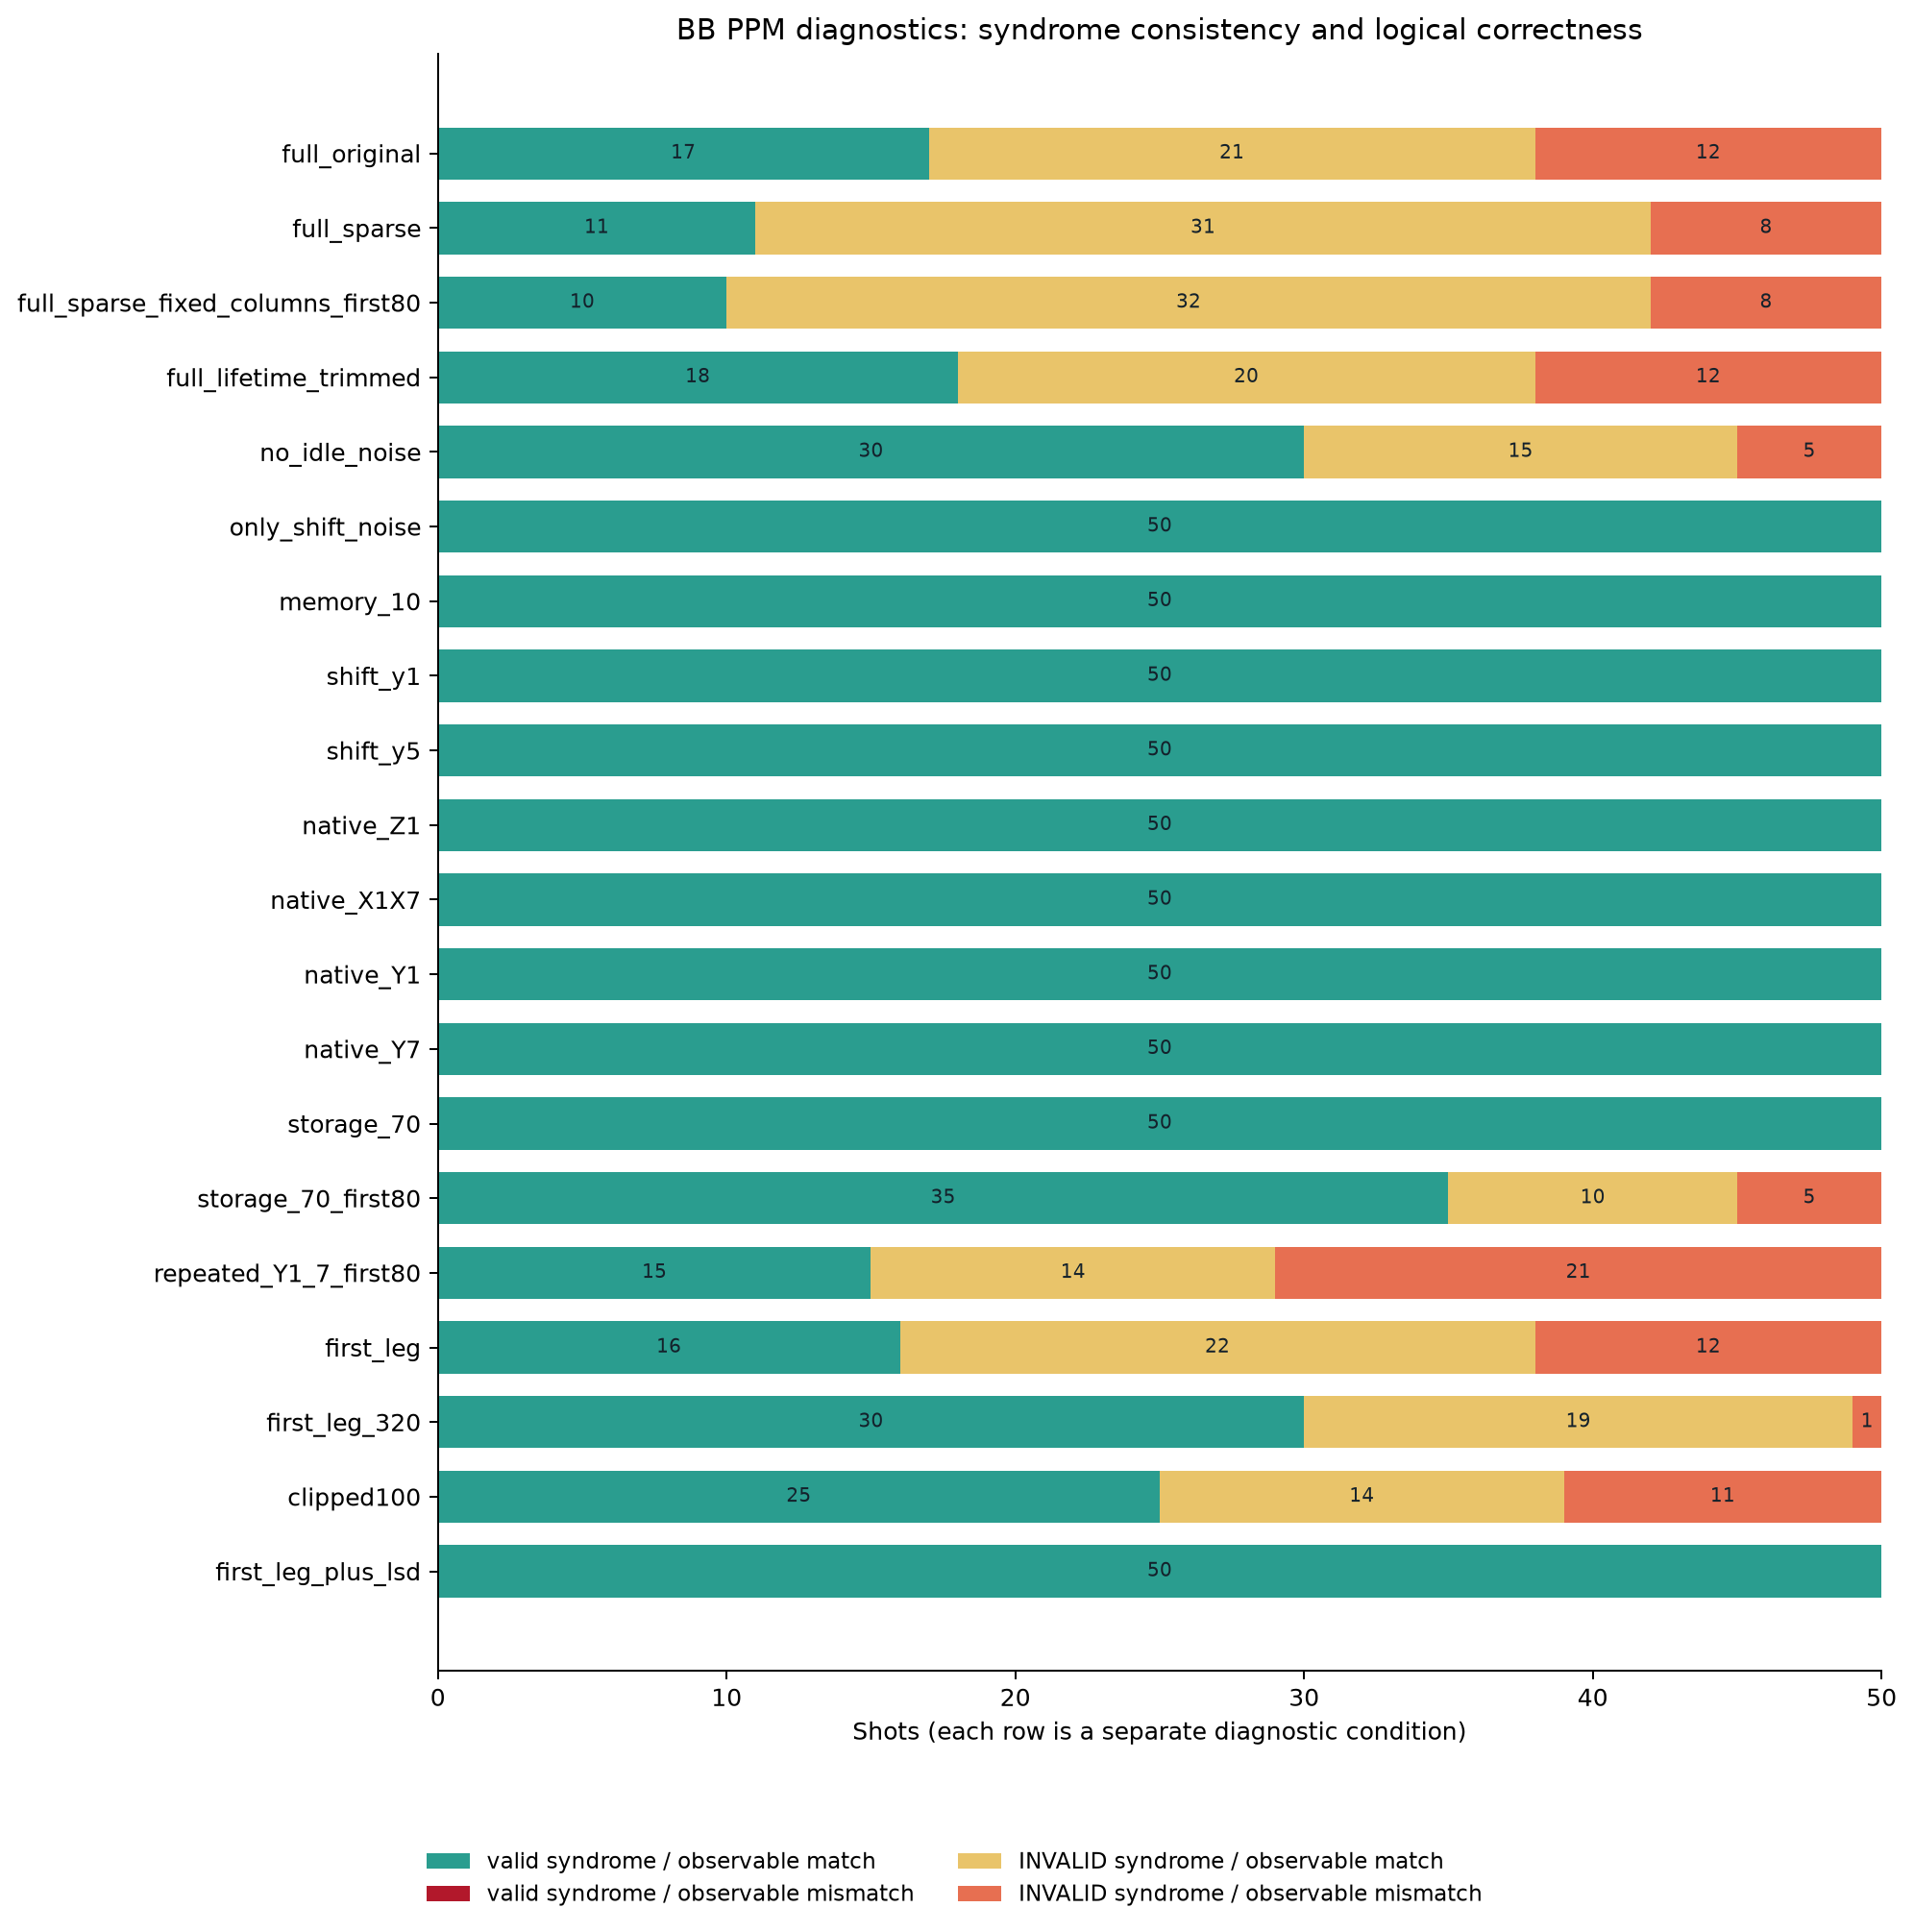

In [4]:
completed = [row for row in DATA['cases'] if row['status'] == 'complete']
if not completed:
    print('No completed cases are available for plotting.')
else:
    labels = ['converged_correct', 'converged_wrong', 'unconverged_correct', 'unconverged_wrong']
    colors = ['#2a9d8f', '#b2182b', '#e9c46a', '#e76f51']
    fig, ax = plt.subplots(figsize=(11.2, max(3.5, 0.48 * len(completed) + 1.7)))
    left = [0] * len(completed)
    positions = list(range(len(completed)))
    for category, color in zip(labels, colors):
        values = [row[category] for row in completed]
        ax.barh(positions, values, left=left, color=color, label={'converged_correct': 'valid syndrome / observable match', 'converged_wrong': 'valid syndrome / observable mismatch', 'unconverged_correct': 'INVALID syndrome / observable match', 'unconverged_wrong': 'INVALID syndrome / observable mismatch'}[category], height=0.7)
        for y, value, x in zip(positions, values, left):
            if value:
                ax.text(x + value / 2, y, str(value), ha='center', va='center', fontsize=8, color='white' if color == '#b2182b' else '#14212b')
        left = [a + b for a, b in zip(left, values)]
    ax.set_yticks(positions, [row['case'] for row in completed])
    ax.invert_yaxis()
    ax.set_xlabel('Shots (each row is a separate diagnostic condition)')
    ax.set_xlim(0, max(row['shots'] for row in completed))
    ax.set_title('BB PPM diagnostics: syndrome consistency and logical correctness')
    ax.spines[['top', 'right']].set_visible(False)
    handles, legend_labels = ax.get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=2, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, min(0.4, 1.0 / fig.get_figheight()), 1, 1))
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=180, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    display(Image(data=buffer.getvalue(), format='png'))


## 单个输入的 Relay 轨迹诊断

这里仅观察原 batch 的 **shot 2**，不产生新的 50-shot LER。phase 划分按 detector 的追加区间；残差表示纠正尚未满足的检查，**不定位物理故障**，也不表示这些 phase 是独立可解的图块。每腿实际终态与 API 最后返回的候选分别展示；全部腿未收敛时，returned result 可能是首 80 次的 fallback，不能代表后续腿终态。大 LLR 本身不等于浮点 overflow；有限性结论只适用于实际观察的腿。

Observed fixed shot: 2 ; observed legs: 20
All observed posteriors finite: True
Globally converged observed legs: 0
Distinct residual supports: 20


,leg,iterations,success,residual_weight,nonfinite,nan,max_finite_abs
0,0,80,False,4,0,0,2.588401e+10
1,1,60,False,670,0,0,2.478313e+04
2,2,60,False,407,0,0,6.580065e+05
3,3,60,False,1069,0,0,2.653798e+04
4,4,60,False,748,0,0,7.578457e+04
5,5,60,False,712,0,0,5.787576e+04
6,6,60,False,887,0,0,2.022486e+04
7,7,60,False,1716,0,0,6.569560e+04
8,8,60,False,1137,0,0,2.008571e+04
9,9,60,False,760,0,0,5.137216e+04


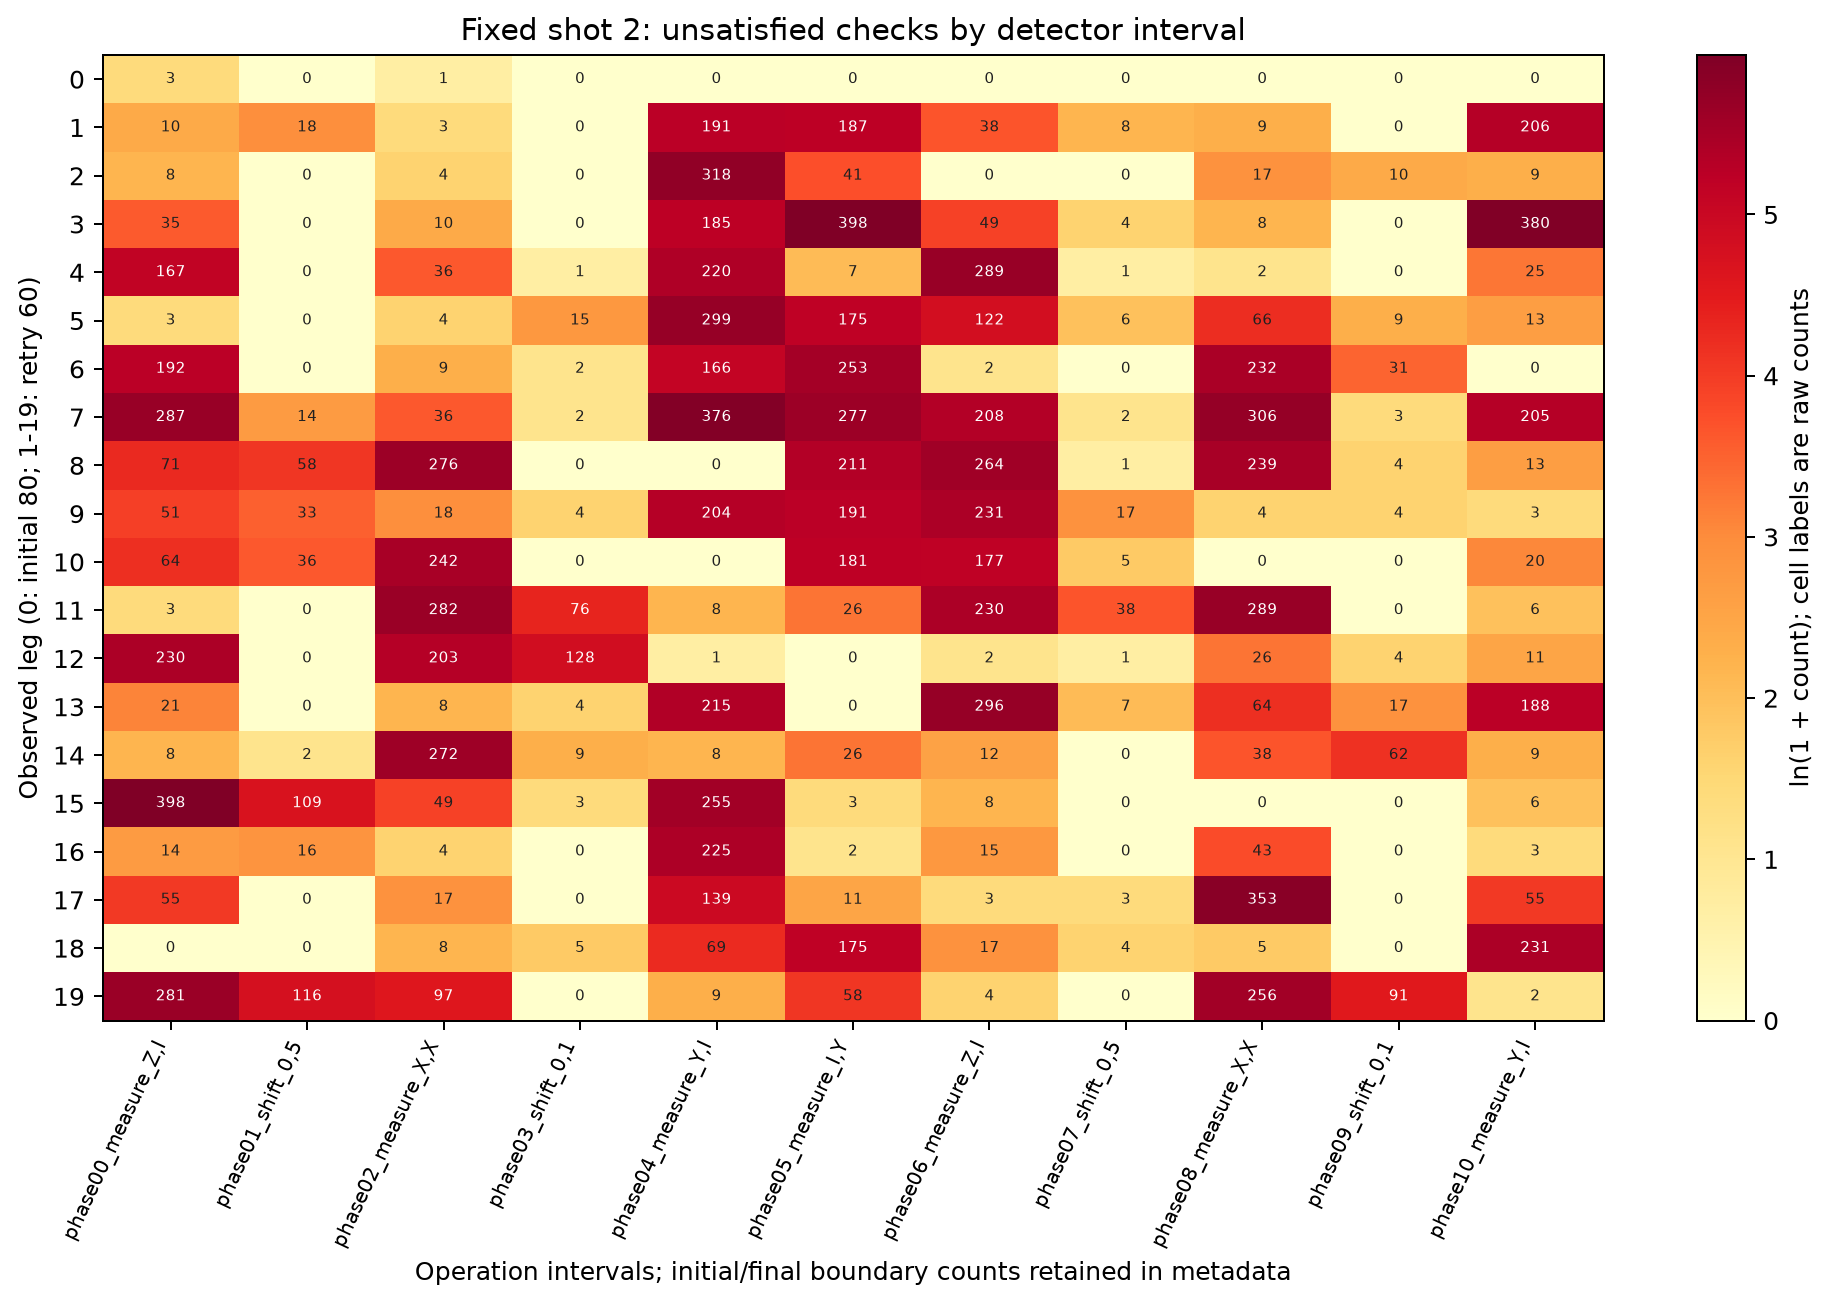

,stage,leg,iterations,success,residual_weight,nonfinite,nan,max_finite_abs
0,original_first_retry60,1,60,False,670,0,0,24783.127413
1,extended_first_retry320,1,320,False,799,0,0,45433.767247


API returned candidate, shown separately from actual retry-leg terminal states:
{
  "success": false,
  "logical_failure": true,
  "residual_weight": 4,
  "iterations": 400,
  "returned_leg_budget": 80,
  "decode_seconds": 137.86159073992167,
  "note": "If neither leg converges, Relay returns the initial first80 candidate; the observed320-leg residual is reported separately."
}


In [5]:
import numpy as np
single = DATA.get('single_shot_diagnostics', {})
phase = single.get('phase_observer', {})
if phase:
    print('Observed fixed shot:', phase['shot_index'], '; observed legs:', phase['observed_leg_count'])
    print('All observed posteriors finite:', phase['all_observed_posteriors_finite'])
    print('Globally converged observed legs:', phase['observed_globally_converged_legs'])
    print('Distinct residual supports:', phase['distinct_residual_supports'])
    columns = ['leg', 'iterations', 'success', 'residual_weight', 'nonfinite', 'nan', 'max_finite_abs']
    with pd.option_context('display.max_rows', None):
        display(pd.DataFrame(phase['observed_legs'])[columns])
    phase_values = pd.DataFrame(phase.get('phase_plot_values', {}))
    if not phase_values.empty:
        # Replot saved counts: no binary image or external file in this code cell.
        values = phase_values.to_numpy()
        fig, ax = plt.subplots(figsize=(11.2, 7.4))
        heatmap = ax.imshow(np.log1p(values), cmap='YlOrRd', aspect='auto')
        ax.set_xticks(range(len(phase_values.columns)), phase_values.columns, rotation=65, ha='right', fontsize=8)
        ax.set_yticks(range(len(values)), range(len(values)))
        ax.set_ylabel('Observed leg (0: initial 80; 1-19: retry 60)')
        ax.set_title('Fixed shot 2: unsatisfied checks by detector interval')
        ax.set_xlabel('Operation intervals; initial/final boundary counts retained in metadata')
        for row in range(values.shape[0]):
            for column in range(values.shape[1]):
                ax.text(column, row, str(values[row, column]), ha='center', va='center',
                        fontsize=6, color='white' if values[row, column] > 75 else '#202020')
        fig.colorbar(heatmap, ax=ax, label='ln(1 + count); cell labels are raw counts')
        fig.tight_layout()
        buffer = io.BytesIO()
        fig.savefig(buffer, format='png', dpi=180, bbox_inches='tight', facecolor='white')
        plt.close(fig)
        display(Image(data=buffer.getvalue(), format='png'))
else:
    print('Final twenty-leg phase observation report pending; partial logs are excluded.')
retry = single.get('retry_counterfactual', {})
if retry:
    comparisons = [dict(stage=key, **retry[key]) for key in ('original_first_retry60', 'extended_first_retry320')]
    display(pd.DataFrame(comparisons)[['stage', 'leg', 'iterations', 'success', 'residual_weight', 'nonfinite', 'nan', 'max_finite_abs']])
    print('API returned candidate, shown separately from actual retry-leg terminal states:')
    print(json.dumps(retry['returned_result'], indent=2))
else:
    print('Final one-shot retry-budget comparison pending.')


## Detector 与低权故障验证

完整性结论有两个共同前提：原 clean 电路通过 `detector_error_model(allow_gauge_detectors=False)` 严格确定性检查且没有错误项，证明声明的 detector 和 observable 都是确定性 parity；独立重算又得到 `rank(D+O)=15514=count_determined_measurements()`。因此 D 与当前 10 个 O 联合张成这份固定无噪电路的全部独立确定性 measurement-record parity 空间。不能仅凭秩的数值相等推出这一结论；D 单独也没有包含 O 增加的 10 个独立方向。

秩和低权搜索本身不验证目标操作的有符号语义；该语义另由下节指定 signed-flow / Choi 检查支持。这里没有证明覆盖论文的 23-observable benchmark，也没有证明物理电路距离为 10。低权搜索的结论仅为当前精确 undecomposed DEM、当前 10 个 observable 下，按 distinct DEM 错误机制计数的距离至少 5；不能换算成物理故障位置距离或 Relay-BP 的 LER 保证。独立源码、fixture、564064 列机制及 rank 复核记录嵌入 `report/detector_evidence_review.json`；该复核没有重跑全量 1–4 机制搜索。

In [6]:
audit = DATA.get('detector_audit', {})
if not audit:
    print('Detector audit pending.')
else:
    complete = audit['deterministic_parity_completeness']
    display(pd.DataFrame([{'measurement_records': complete['num_measurements'], 'detector_rows': complete['num_detectors'], 'detector_rank': complete['detector_rank'], 'observables': complete['num_observables'], 'combined_rank': complete['combined_record_rank'], 'all_determined_relations': complete['count_determined_measurements']}]))
    print('All independent deterministic measurement parities covered:', complete['deterministic_record_relation_space_complete'])
    faults = audit['low_weight_fault_checks']
    print('Exhaustive 4-mechanism coverage complete:', faults['four_fault_exhaustive_coverage_complete'])
    print('DEM logical-fault distance lower bound:', faults['logical_fault_distance_in_DEM_metric_at_least'])
    print('Limit:', faults['limits'])
    bounded = audit.get('bounded_physical_witness_search', {})
    print('Bounded physical-witness search:', bounded.get('status', 'not available'), '; wall limit:', bounded.get('wall_timeout_seconds', bounded.get('external_wall_limit_seconds')), 's; one CPU thread')
    print('A 115-second timeout does not provide an additional distance lower bound.')
    sparse = audit['sparse_detector_control']
    overlap = audit.get('tanner_graph_overlap', {})
    display(pd.DataFrame([{'representation': name, 'H_nonzeros': sparse[key]['nnz'], 'max_error_detector_degree': sparse[key]['column_max'], 'Tanner_4_cycles': overlap.get(label, {}).get('tanner_four_cycle_count')} for name, key, label in [('original', 'original_H', 'original'), ('equivalent sparse', 'transformed_H', 'sparse')]]))


,measurement_records,detector_rows,detector_rank,observables,combined_rank,all_determined_relations
0,15969,15510,15504,10,15514,15514


All independent deterministic measurement parities covered: True
Exhaustive 4-mechanism coverage complete: True
DEM logical-fault distance lower bound: 5
Limit: This concerns weights of distinct columns of the exact full undecomposed DEM and the 10 current observables. It does not prove distance 10, bound Relay-BP failure rates, or certify equivalence to the paper physical circuit or 23-correlator benchmark.
Bounded physical-witness search: timed_out ; wall limit: 115 s; one CPU thread
A 115-second timeout does not provide an additional distance lower bound.


,representation,H_nonzeros,max_error_detector_degree,Tanner_4_cycles
0,original,4329031,23,941260508
1,equivalent sparse,4243165,18,715935300


## 当前默认 PPM 的有符号目标语义

独立审查从保存的 plan 精确重建原 clean 电路，并核查操作段的反馈只引用段内测量。原默认 X 初始化下，目标 `+X2 Z7 X12` 的输出/记录关系与 10 个应保留 X 关系通过。另用独立编码 Choi 边界，分别在 `+Z1` 和与原默认匹配的 `+X1` pivot 输入下，检查 **11 个数据 logical（pivot 消耗），21 个与目标交换的 Bell 关系 + 2 个 target/record 关系**，以及 144 项声明的正 codespace checks；错误负号与不交换 Bell 关系作为负对照被拒绝。

这些指定检查支持当前默认操作的目标测量语义与数据关联保持，**不是论文 23-observable benchmark 的复现**。原 LER 数据仍使用 10 个 observable，未被换成 Choi 数据。`has_flow(unsigned=False)` 每项内部使用 256 次随机 stabilizer 代数检验，文档给出的单项误接受上界为 $2^{-256}$；这是代数核验，不是物理噪声采样，不是严格确定性符号枚举。它不证明论文 schedule 一致、物理距离 10 或低 LER，也不证明被消耗 pivot 的逻辑通道保持。

In [7]:
signed = DATA.get('signed_flow_review', {})
if not signed:
    print('Targeted signed-flow review pending.')
else:
    checks = [
        {'check': 'Saved plan reconstructs the exact original clean circuit', 'passed': signed['exact_circuit_validation']['rebuilt_from_saved_plan_exactly_equals_original']},
        {'check': 'Default X input: target/record + 10 preserved X relations', 'passed': signed['actual_default_all_selected_signed_flows_passed']},
        {'check': 'Choi with +Z1 pivot: 11 data logicals, 21 Bell + 2 target/record relations', 'passed': signed['choi_all_23_selected_signed_flows_passed']},
        {'check': 'All 144 declared output codespace checks positive', 'passed': signed['choi_output_codespace_all_144_declared_checks_positive']},
        {'check': 'Wrong target/output signs rejected', 'passed': signed['actual_default_wrong_target_sign_rejected'] and signed['choi_wrong_output_sign_rejected']},
        {'check': 'Noncommuting initial Bell relation correctly rejected', 'passed': signed['choi_noncommuting_initial_bell_correlation_not_preserved']},
    ]
    extra = signed.get('choi_pivot_X_additional_check', {})
    checks.append({'check': 'Choi with default +X1 pivot: same 21 + 2 relations, codespace and negative controls', 'passed': all(extra.get(key, False) for key in ('all_23_selected_signed_flows_passed', 'positive_codespace_all_checks_passed', 'wrong_target_sign_rejected', 'noncommuting_bell_not_preserved'))})
    with pd.option_context('display.max_colwidth', None):
        display(pd.DataFrame(checks))
    print(signed['verification_caveat'])
    print('New physical samples:', signed['new_physical_samples'], '; decoder calls:', signed['decoder_calls'])
    print('Data logicals:', signed['choi_scope']['encoded_data_qubits'], '; disposable pivot:', signed['choi_scope']['consumed_pivot'])
    print('Original saved LER metric: 10 observables; unchanged.')


,check,passed
0,Saved plan reconstructs the exact original clean circuit,True
1,Default X input: target/record + 10 preserved X relations,True
2,"Choi with +Z1 pivot: 11 data logicals, 21 Bell + 2 target/record relations",True
3,All 144 declared output codespace checks positive,True
4,Wrong target/output signs rejected,True
5,Noncommuting initial Bell relation correctly rejected,True
6,"Choi with default +X1 pivot: same 21 + 2 relations, codespace and negative controls",True


Stim unsigned=False checks use 256 randomized stabilizer algebra tests internally (documented false-positive bound 2^-256 per accepted check). These are not noise/shots/LER sampling. No claim of deterministic symbolic enumeration is made.
New physical samples: 0 ; decoder calls: 0
Data logicals: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] ; disposable pivot: 1
Original saved LER metric: 10 observables; unchanged.


## 核查结论与剩余限度

**本轮 20 项诊断全部完成，每项统计覆盖 50 个样本；其中同输入的 decoder 对照复用样本，不是 20 批相互独立的采样。** 原始四个噪声点的结果、参数、代码和已保存输出均保留。

已经定位到一个能直接复现的主要失败机制：**当前完整 PPM 电路上，参考 Relay-BP 大量不收敛，最终返回首轮 BP 的无效纠正。** 这比“电路较长”或“样本较少”的解释更具体；尚未把引起不收敛的底层差异唯一定位到某一行代码、某个图结构指标或论文未公开的调度细节。

1. **完整参数重试没有救回这批逻辑错误。** 保持 `pre_iter=80`、`num_sets=600`、`set_max_iter=60`、`stop_nconv=5` 及其余参考参数，完整 PPM 在 $p=0.001$ 的 50 个保存样本中得到 17 个有效正确纠正、21 个无效但 observable 匹配、12 个无效且 observable 不匹配。33 个无效结果全部用完 $80+600\times60=36080$ 次迭代，其 correction 与返回 posterior 都逐位等于首 80 次 BP 的 fallback。12 个失败 ID 与同批 first80 完全相同；600 次重试只额外使 shot 12 满足校验，其 observable 原本已匹配。完整运行和 first80 的 50 个 observable 预测全部相同，49 个 correction 相同。

   这次 12/50 再现了历史 sweep 的计数，但历史逐 shot 原始输入未保存，不能仅凭数值相同声称与历史样本逐位相同。上述逐位结论只针对本轮保留并经独立校验的同一批输入。

2. **更换 decoder 能纠正这些相同输入。** 下表的 H、O、先验、错误变量列序和 50 个输入完全相同；真值只用于评分。

   | 解码条件 | 有效且逻辑正确 | 无效、observable 匹配 | 无效、observable 不匹配 |
   |---|---:|---:|---:|
   | 参考完整 Relay-BP | 17 | 21 | 12 |
   | 仅首 80 次 BP | 16 | 22 | 12 |
   | 仅首轮最多 320 次 BP | 30 | 19 | 1 |
   | 完整 Relay，另加限幅 100 | 25 | 14 | 11 |
   | 首 80 次 BP 的保存后验接 LSD | 50 | 0 | 0 |

   这些条件均未出现“满足 syndrome 但 observable 错误”的样本。首轮 320 的最后一个 observable 错误为 shot 39；它复用 16 个已有效早停的 first80 结果，其余 34 个确实运行更长首轮。相对完整参考配置，它救回 14 个无效纠正，但失去 shot 12 的有效收敛；不能把所有指标描述为逐样本单调改善。401.568 秒是来源运行 wall time 总和，包含重算，不是一次独立 320×50 运行速度。

   LSD 使全部 33 个参考配置的无效纠正变为有效且逻辑正确，也纠正了全部 12 个 observable 错误，独立 Hc/Oc 复算已通过。这说明该批错误并非在当前受测逻辑关联下无法找到正确纠正。**320、限幅和 LSD 都是改变 decoder 的诊断，不能替代或冒充论文参数的基线。** 50 次零失败的一侧 95% 上界约为 5.82%，远不能验证 $10^{-5}$、$10^{-9}$ 或 $10^{-11}$ 的真实 LER。

3. **计数口径会掩盖解码失败。** [论文 Appendix A.7](https://arxiv.org/html/2506.03094v1#A7) 先要求 $Hc=s$，再检查 $Ac=Ae$。原 Sinter 计数只比较 observable，因此原 12/50 保留为 observable-mismatch rate；另行报告 33/50 无效纠正。21 个 observable 恰好匹配的无效结果不能称作有效纠错成功，也不能把 33/50 静默替换成原图的 LER。各控制表的这两类数量可能重叠，不能相加。

4. **电路、时序与 detector 对照缩小了原因范围。** 完整 600-set 的 isolated native Z1、Y1、Y7、X1X7，两个 isolated shift、memory10，以及仅 shift 区间有噪声的控制，各自 50/50 有效且正确。storage70 的同一批输入从 first80 的 35 个有效正确、10 个无效但观测匹配、5 个无效且观测错误，改善为完整 Relay 的 50/50 有效正确。这排除了“长度增加必然导致当前现象”或“Relay 在所有长电路上都失效”的解释。repeated_Y1_7 只做了 first80 截断控制（15/14/21），未声称完成其 600-set 控制。

   完整序列去掉 68,460 个可避免的测量辅助比特 idle 暴露后，结果为 18 个有效正确、20 个无效但观测匹配、12 个无效且观测错误；全部去掉 idle 噪声后为 30/15/5。这两个新采样批次不是同 shot 配对，不能把同为 12/50 当成“时序优化没有收益”的证明；但问题在减少乃至删除 idle 后仍存在，idle 不是唯一原因。时序控制通过实际门重排、测量记录映射与原 NoiseInjector 重注噪验证，不只是人为改先验。

   可逆 detector 换基底的完整结果为 11/31/8，39 个纠正仍无效。全部 564,064 列已验证 $H_s=(TH_0)[:,p]$、$O_s=O_0[:,p]$ 和先验列置换，其中 28,818 列位置改变；全部输入满足 $s_s=Ts_0$，真值不变。将 correction 拉回原列后，全部有效性与逻辑预测也一致。因此这是等价表示对照，但同时改变 detector 基底与变量顺序，不能把差异只归于换基底。只换基底、严格固定原列序的 first80 控制为 10/32/8；虽然 observable 错误较少，无效结果反而更多。两者都没有解决收敛问题。

   换基底减少约 23.94% 的 4-cycles，但只减少约 1.98% 的 H 边；native_Y1 同样有高阶 check 却全部成功。短环、高度数或电路长度各自都不足以单独定因。全图只有一个含错误变量的连通分量，不能按 instruction 直接拆成独立解码块。

5. **没有证据支持几个容易误判的实现错误。** 保存噪声电路已独立逐指令重构，并与原 NoiseInjector 重注噪精确一致；$p=0.001$ 是退极化总概率，SPAM 的翻转概率为 p，符合论文 §2.6，未误用 p/3、p/15 或 2p/3。论文 A.7 的等 q 故障复制与当前真实退极化和合并 DEM 表示仍有差别：单位置通道一阶相同、二阶不同，BP 对拆分/合并表示的敏感性未因此排除。论文原 graph-coloring 调度并未完全复现。

   clean 电路通过严格 DEM 确定性检查，且 `rank(D+O)=15514=count_determined_measurements()`，支持当前固定电路的 D 与 10 个 O 没有漏掉独立确定性测量关系。6 个可选冗余 detector 均为 H 零行、保存 syndrome 全零，删除它们不改变图边或短环。当前精确 DEM 下未发现由 1–4 个 distinct 错误机制构成的无 syndrome 逻辑错误，即 `d_DEM>=5`；这不是物理距离 10 的证明，限时物理 witness 搜索也没有给出额外证明。

   独立有符号语义审查从原保存 plan 精确重建 clean 电路，检查目标 `+X2 Z7 X12`、应保留的 X 关联，以及 11 个数据 logical 的 Choi 边界（21 个交换 Bell 关系和 2 个 target/record 关系），错误符号负对照被拒绝。`has_flow(unsigned=False)` 使用随机 stabilizer 代数检验，单项误接受上界为 $2^{-256}$；没有额外物理采样。它支持本操作的理想目标与数据关联，不是论文完整含噪 23-observable benchmark，也不证明论文调度或物理距离。

6. **大 LLR 与浮点溢出不是同一件事。** shot 2 前 20 腿的所有观察值均有限；20 腿均未全局收敛，首腿残差 4，后续腿残差 324–1716，残差集合不同且交集为空。这些 detector 区域不是物理故障位置。相同 shot、相同首个重试 gamma，将重试预算从 60 加到 320，实际腿残差从 670 变为 799，仍失败；API 返回的残差 4 是首轮 fallback，不能混作该重试腿终态。

   完整限幅 100 对照仍有 11 个逻辑错误和 25 个无效纠正；相对 baseline 救回逻辑失败 shot 15、39，却新增 shot 28 的逻辑失败。它改善了部分有效收敛，未消除现象，不支持把主要原因直接归结为“大数值溢出”。有限性检查仅覆盖观察腿或返回后验，不伪称观察了每个样本所有中间腿。

**与论文 Table 2 的关系：** 论文的 gross 原生 in-module measurement 在 $p=10^{-3}$ 为约 $10^{-5}$，在 $p=10^{-4}$ 为约 $10^{-9}$；方括号 $[10^{-11}]$ / $[10^{-20}]$ 是 two-gross 的假设值，不能拿来直接比较当前 gross 完整复合 PPM。[Table 2](https://arxiv.org/html/2506.03094v1#S1.T2) 与 [A.7](https://arxiv.org/html/2506.03094v1#A7) 的单指令、Bell-reference、failure-spectrum/importance-sampling 统计也不同于这里的完整 7 次 native measurement 加 4 次 shift、10 observable、50-shot 基线。仅这些范围差异仍不足以解释 0.24；本轮同输入解码对照已提供具体的失败机制证据。

作者公开的 bicycle-architecture-compiler 在已核查的提交/分支中提供编译和资源估算，错误率由模型预设，未提供能够逐门复现上述物理 Monte Carlo 的代码。现代 Relay 公式、当前 API 参数与调用已核对；作者旧参数后端的全部实现细节未得到独立证明。**因此结论是：当前高 observable-mismatch rate 的直接机制已定位为完整组合电路上的 Relay 不收敛和 fallback；尚不能声称复现论文低 LER，或已找到唯一的底层代码 bug。**

本报告由已完成的保存数据生成，执行显示单元不采样、不解码。中断过的旧尝试不计入结果；恢复任务复用原输入、逐 shot 保存。不同并发负载、运行边界和后处理阶段的耗时不能作算法速度排名。全部同输入 decoder 结果及三个完整电路/噪声控制均已独立复算 Hc/Oc；源码、摘要、逐样本分类、哈希及验证范围保存在 Notebook metadata。


## 参数、来源与复查

完整 manifest、summary、逐 shot 记录、静态报告、脚本源码及 SHA-256 保存在 Notebook metadata 的 `bb_ppm_diagnostics` 中。下方只显示相对路径。

In [8]:
print('Reference Relay-BP parameters used in these runs:')
print(json.dumps(DATA['paper_parameters'], indent=2))
parameter_rows = [{'case': row['case'], 'parameters': json.dumps(row['decoder_parameters'], sort_keys=True) if row['decoder_parameters'] else row['decoder_change'], 'seconds_scope': row['seconds_scope']} for row in DATA['cases']]
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(pd.DataFrame(parameter_rows))
    display(pd.DataFrame(DATA['source_files']))
print('Original experiment files modified by this reporting run: no')
print('Sampling calls in this Notebook: 0; decoder calls: 0')


Reference Relay-BP parameters used in these runs:
{
  "alpha": 1.0,
  "gamma0": 0.125,
  "pre_iter": 80,
  "num_sets": 600,
  "set_max_iter": 60,
  "gamma_dist_interval": [
    -0.24,
    0.66
  ],
  "stop_nconv": 5,
  "stopping_criterion": "nconv"
}


,case,parameters,seconds_scope
0,full_original,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}","Wall time of this final checkpointed execution attempt, including worker initialization and collection; earlier interrupted attempts are listed separately in manifest."
1,full_sparse,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation
2,full_sparse_fixed_columns_first80,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 0, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation
3,full_lifetime_trimmed,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation
4,no_idle_noise,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation
5,only_shift_noise,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation
6,memory_10,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation
7,shift_y1,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation
8,shift_y5,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation
9,native_Z1,"{""alpha"": 1.0, ""gamma0"": 0.125, ""gamma_dist_interval"": [-0.24, 0.66], ""logging"": false, ""num_sets"": 600, ""pre_iter"": 80, ""seed"": 0, ""set_max_iter"": 60, ""stop_nconv"": 5, ""stopping_criterion"": ""nconv""}",decoder wall time; excludes preparation


,case,path,sha256
0,full_original,decoder/full_original_p001_resumed/manifest.json,1329b02a2e7ffd9a208e133d2af31fbdc7617a40d9f6be626d52c32f70b925a8
1,full_original,decoder/full_original_p001_resumed/summary.json,27180ef9108a2acf1967ba7197786b392e0fa842e69488be8ab8b88985e148d7
2,full_original,decoder/full_original_p001_resumed/shots.json,16dafd9aa1d053335134a06c82f48257a5ab7672fc4cf57b20b772f69c6203d6
3,full_sparse,runs/full_sparse/manifest.json,16447b01207d594c0e4baf51cf2fbcd41c1b9b33c4686879d460330bdd6e66e8
4,full_sparse,runs/full_sparse/summary.json,3527186e484803cbf4dbaf6dbbb3c4596d17835d6a4152065edb7091d218f5a9
5,full_sparse,runs/full_sparse/shots.json,0bee0fa1eb3865e45a4484289e58ae40c8a51f80404a45de85ed8f4dd2aeb20a
6,full_sparse_fixed_columns_first80,runs/full_sparse_fixed_columns_first80/manifest.json,65a541b8b71e98a6077e533aea10086706f81ae1ac34e04ec3da588af70de82c
7,full_sparse_fixed_columns_first80,runs/full_sparse_fixed_columns_first80/summary.json,f3fcbc525b0a81636d55a74ffde02532ded41db66d7e22cdc71608c531c55439
8,full_sparse_fixed_columns_first80,runs/full_sparse_fixed_columns_first80/shots.json,373be987a64684e6b4bfb5686f1b9df424d4c1c3a340ac3777244528d0e30bca
9,full_lifetime_trimmed,runs/full_lifetime_trimmed/manifest.json,03a0c027cb4b64d036369bf0baa77d9c903aa24adfca6e4eea73120e15840ae4


Original experiment files modified by this reporting run: no
Sampling calls in this Notebook: 0; decoder calls: 0
